### Traditional RUL estimation taking the cycle_summary sample data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cycle_summary = pd.read_csv(r"C:\Users\suman\Documents\meatech-battery-analytics-case-study\data\processed\cycle_summary.csv")  
WINDOW      = (2, 6)                # early cycles we "pretend" to have (cycle 1 = pre-test discharge, skipped)
FRAC        = 0.80                  # end-of-life = 80 % given data
REF_CYCLE   = 2                     # Assume the capacity at this cycle (first full charge+discharge cycle)
CONSEC      = 3                     # true EOL = capacity stays below threshold for this many cycles in a row

In [14]:
summary = cycle_summary.loc[
    cycle_summary["has_discharge"]
    & cycle_summary["Cycle_Index"].ge(REF_CYCLE)
].dropna(subset=["discharge_capacity_ah"])

caps = {}
early = {}
thr = {}

for run, group in summary.groupby("run_id"):
    cap = group.sort_values("Cycle_Index").set_index("Cycle_Index")[
        "discharge_capacity_ah"
    ]
    caps[run] = cap
    reference_ah = cap.loc[REF_CYCLE]
    early[run] = cap.loc[WINDOW[0]:WINDOW[1]]
    thr[run] = FRAC * cap.loc[REF_CYCLE]

    display(early[run].to_frame())
    print(f"{run}: {FRAC:.0%} of cycle-{REF_CYCLE} capacity: {reference_ah:.3f} Ah = {thr[run]:.4f} Ah")

print("\nAssignment threshold: 80% of 2.5 Ah nominal = 2.000 Ah")

,discharge_capacity_ah
Cycle_Index,
2,1.687
3,1.662
4,1.644
5,1.627
6,1.621


LR1865SZ_cycles201214_002_4: 80% of cycle-2 capacity: 1.687 Ah = 1.3496 Ah


,discharge_capacity_ah
Cycle_Index,
2,1.512
3,1.457
4,1.418
5,1.411
6,1.360


LR1865SZ_cycles201217_001_2: 80% of cycle-2 capacity: 1.512 Ah = 1.2096 Ah

Assignment threshold: 80% of 2.5 Ah nominal = 2.000 Ah


### Fit best straight line by hand

In [5]:
fit = {}

for run, e in early.items():
    x = e.index.to_numpy(dtype=float)  # Cycle numbers
    y = e.to_numpy(dtype=float)       # Discharge capacity in Ah

    slope, intercept = np.polyfit(x, y, deg=1)
    fit[run] = (slope, intercept)

    print(run)
    print(f"  Slope: {slope:+.4f} Ah/cycle")
    print(f"  Intercept: {intercept:.4f} Ah")
    print(f"  Fitted line: capacity = {intercept:.4f} {slope:+.4f} × cycle\n")

LR1865SZ_cycles201214_002_4
  Slope: -0.0167 Ah/cycle
  Intercept: 1.7150 Ah
  Fitted line: capacity = 1.7150 -0.0167 × cycle

LR1865SZ_cycles201217_001_2
  Slope: -0.0350 Ah/cycle
  Intercept: 1.5716 Ah
  Fitted line: capacity = 1.5716 -0.0350 × cycle



### Extend the line to the threshold

In [15]:
pred_eol = {}

for run, (slope, intercept) in fit.items():
    pred_eol[run] = np.nan

    if slope >= 0:
        print(f"{run}: No downward crossing predicted.")
        continue

    crossing = (thr[run] - intercept) / slope
    if crossing <= WINDOW[1]:
        print(f"{run}: The fitted line reaches the threshold by cycle {crossing:.1f}, within or before the fitting window.")
        continue

    pred_eol[run] = crossing
    print(f"{run}: Predicted crossing at cycle {crossing:.1f}")

LR1865SZ_cycles201214_002_4: Predicted crossing at cycle 21.9
LR1865SZ_cycles201217_001_2: Predicted crossing at cycle 10.3


True EOL from the full data

In [16]:
def true_eol(cap, threshold, consec=CONSEC):
    for cycle in cap.index:
        before = cap.get(cycle - 1, np.nan)
        below = cap.reindex(range(cycle, cycle + consec))

        if before >= threshold and below.lt(threshold).all():
            first_below = below.iloc[0]
            fraction = (before - threshold) / (before - first_below)
            crossing = cycle - 1 + fraction
            return cycle, crossing

    return np.nan, np.nan


true_eol_i, true_eol_f = {}, {}

for run, cap in caps.items():
    first_below, crossing = true_eol(cap, thr[run])
    true_eol_i[run] = first_below
    true_eol_f[run] = crossing

    if pd.isna(crossing):
        print(f"{run}: No confirmed crossing in the measurements.")
        continue

    print(f"{run}: First cycle below threshold = {first_below}")
    print(f"  Interpolated crossing = {crossing:.1f}\n")

LR1865SZ_cycles201214_002_4: First cycle below threshold = 24
  Interpolated crossing = 23.3

LR1865SZ_cycles201217_001_2: First cycle below threshold = 12
  Interpolated crossing = 12.0



In [19]:
last = WINDOW[1]
rows = []

for run in caps:
    slope, _ = fit[run]
    predicted_eol = pred_eol[run]
    measured_eol = true_eol_f[run]
    predicted_rul = predicted_eol - last
    measured_rul = measured_eol - last
    error = predicted_rul - measured_rul

    rows.append({
        "Run": run.removeprefix("LR1865SZ_cycles"),
        "Fade rate (Ah/cycle)": round(-slope, 3),
        "80% of cycle-2 capacity (Ah)": round(thr[run], 4),
        "Predicted EOL cycle": round(predicted_eol, 1),
        "Estimated EOL cycle from measurements": round(measured_eol, 1),
        f"Predicted RUL at cycle {last}": round(predicted_rul, 1),
        f"Estimated RUL at cycle {last} from measurements": round(measured_rul, 1),
        "RUL error (cycles)": round(error, 1),
        "Relative RUL error (%)": (
            round(100 * error / measured_rul, 1) if measured_rul > 0 else np.nan
        ),
    })

table = pd.DataFrame(rows).set_index("Run").T
display(table)

Run,201214_002_4,201217_001_2
Fade rate (Ah/cycle),0.0170,0.0350
80% of cycle-2 capacity (Ah),1.3496,1.2096
Predicted EOL cycle,21.9000,10.3000
Estimated EOL cycle from measurements,23.3000,12.0000
Predicted RUL at cycle 6,15.9000,4.3000
Estimated RUL at cycle 6 from measurements,17.3000,6.0000
RUL error (cycles),-1.4000,-1.6000
Relative RUL error (%),-8.0000,-27.1000


The straight-line fit used cycles 2–6 to predict when each run would reach 80% of its measured cycle-2 capacity. It underestimated remaining life in both runs by 1.4 cycles (8.0%) and 1.6 cycles (27.1%), respectively. The second run had a steeper early fade rate and fewer cycles remaining, so a similar error in cycles was a much larger percentage error.

Both runs were already below 80% of nominal capacity (2.0 Ah) at cycle 2. The errors in this table therefore apply to the cycle-2 benchmark.

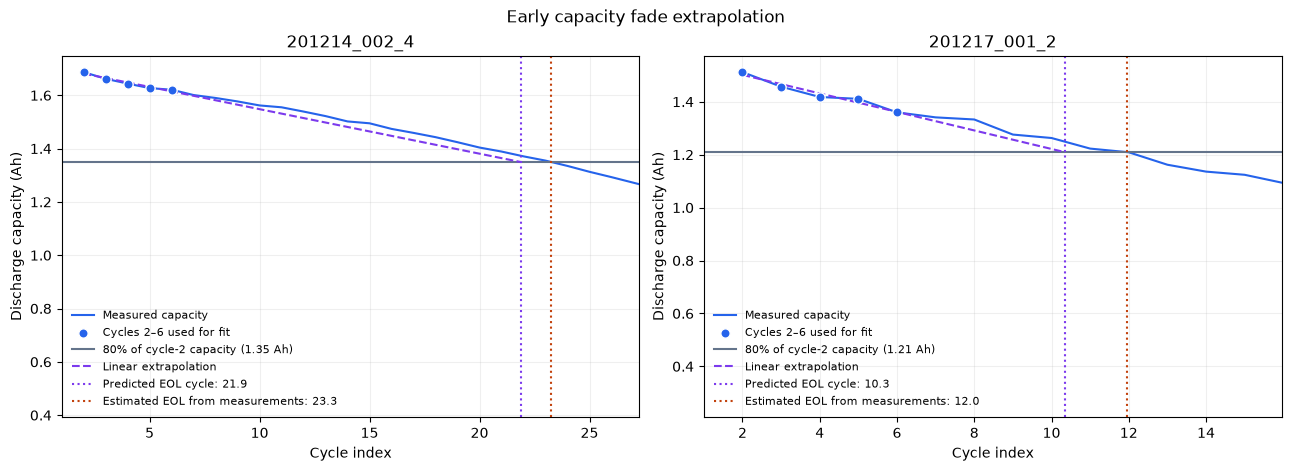

In [20]:
fig, axes = plt.subplots(
    1, len(caps), figsize=(6.4 * len(caps), 4.6),
    squeeze=False, layout="constrained",
)

for ax, (run, cap) in zip(axes[0], caps.items()):
    slope, intercept = fit[run]
    predicted = pred_eol[run]
    measured = true_eol_f[run]
    threshold = thr[run]

    ax.plot(cap.index, cap, color="#2563EB", label="Measured capacity")
    ax.scatter(
        early[run].index, early[run],
        color="#2563EB", edgecolor="white", s=45, zorder=3,
        label=f"Cycles {WINDOW[0]}–{WINDOW[1]} used for fit",
    )
    ax.axhline(
        threshold, color="#64748B",
        label=f"80% of cycle-{REF_CYCLE} capacity ({threshold:.2f} Ah)",
    )

    if np.isfinite(predicted):
        x_line = np.array([WINDOW[0], predicted])
        ax.plot(
            x_line, slope * x_line + intercept, "--",
            color="#7C3AED", label="Linear extrapolation",
        )
        ax.axvline(
            predicted, color="#7C3AED", linestyle=":",
            label=f"Predicted EOL cycle: {predicted:.1f}",
        )

    if np.isfinite(measured):
        ax.axvline(
            measured, color="#C2410C", linestyle=":",
            label=f"Estimated EOL from measurements: {measured:.1f}",
        )

    eol_cycles = [cycle for cycle in (predicted, measured) if np.isfinite(cycle)]
    if eol_cycles:
        ax.set_xlim(WINDOW[0] - 1, max(eol_cycles) + 4)

    ax.set(
        title=run.removeprefix("LR1865SZ_cycles"),
        xlabel="Cycle index",
        ylabel="Discharge capacity (Ah)",
    )
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)

fig.suptitle("Early capacity fade extrapolation")
plt.show()

In [22]:
for run, cap in caps.items():
    nominal_ah = cycle_summary.loc[
        cycle_summary["run_id"].eq(run), "nominal_capacity_ah"
    ].dropna().iloc[0]

    print(f"\n{run}")
    for label, threshold in [
        ("80% of nominal", FRAC * nominal_ah),
        ("80% of cycle-2 capacity", thr[run]),
    ]:
        below = cap[cap > threshold]
        print(f"{label} ({threshold:.4f} Ah), {len(below)} of {len(cap)} cycles")
        print(below.index.tolist())


LR1865SZ_cycles201214_002_4
80% of nominal (2.0000 Ah), 0 of 99 cycles
[]
80% of cycle-2 capacity (1.3496 Ah), 22 of 99 cycles
[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]

LR1865SZ_cycles201217_001_2
80% of nominal (2.0000 Ah), 0 of 99 cycles
[]
80% of cycle-2 capacity (1.2096 Ah), 10 of 99 cycles
[2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


### 2. Discharge-curve feature extraction for Feature-based modeling 

In [23]:
measurements = pd.read_csv(
    r"C:\Users\suman\Documents\meatech-battery-analytics-case-study\data\processed\measurements_clean.csv",
    usecols=["run_id", "Cycle_Index", "phase", "Capacity(Ah)", "Voltage(V)"],
)

discharge = measurements.loc[measurements["phase"].eq("discharge")]

def discharge_curve(run_id, cycle):
    """Return discharged capacity indexed by voltage."""
    points = discharge.loc[
        discharge["run_id"].eq(run_id) & discharge["Cycle_Index"].eq(cycle)
    ].dropna(subset=["Voltage(V)", "Capacity(Ah)"])

    return points.groupby("Voltage(V)")["Capacity(Ah)"].mean().sort_index()

curve_pairs = {
    run_id: (discharge_curve(run_id, 2), discharge_curve(run_id, 6))
    for run_id in caps
}

In [24]:
# Use one voltage grid covered by both cycles in both runs.
all_curves = [curve for pair in curve_pairs.values() for curve in pair]
if any(len(curve) < 2 for curve in all_curves):
    raise ValueError("Each run needs valid discharge curves at cycles 2 and 6.")

lower_v = max(curve.index.min() for curve in all_curves)
upper_v = min(curve.index.max() for curve in all_curves)
if lower_v >= upper_v:
    raise ValueError("The discharge curves have no shared voltage interval.")

voltage_grid = np.linspace(lower_v, upper_v, 200)

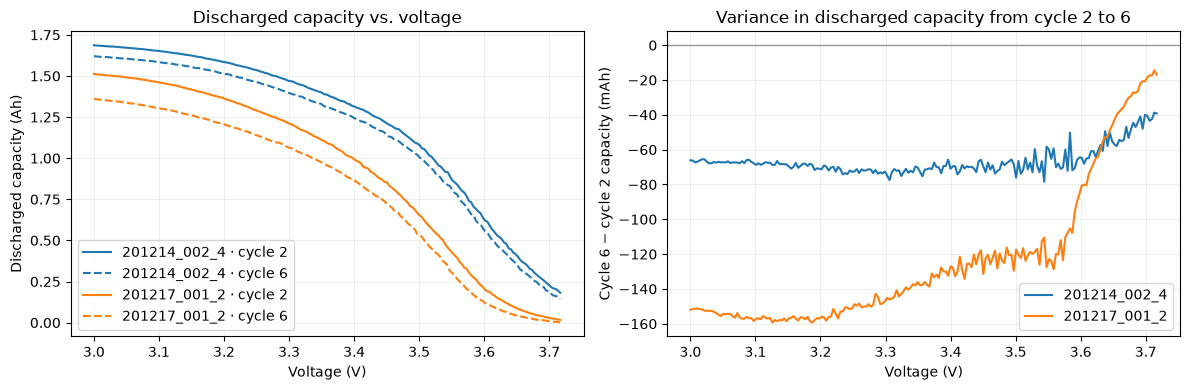

,run_id,Delta Q variance (Ah²),Measured EOL cycle
0,LR1865SZ_cycles201214_002_4,0.000062,23.270000
1,LR1865SZ_cycles201217_001_2,0.001608,11.957143


In [27]:
fig, (ax_curves, ax_delta) = plt.subplots(1, 2, figsize=(12, 4))
rows = []

for run_id, (cycle_2, cycle_6) in curve_pairs.items():
    label = run_id.removeprefix("LR1865SZ_cycles")
    q2 = np.interp(voltage_grid, cycle_2.index, cycle_2.to_numpy())
    q6 = np.interp(voltage_grid, cycle_6.index, cycle_6.to_numpy())
    delta_q = q6 - q2

    line, = ax_curves.plot(voltage_grid, q2, label=f"{label} · cycle 2")
    ax_curves.plot(
        voltage_grid, q6, "--", color=line.get_color(),
        label=f"{label} · cycle 6",
    )
    ax_delta.plot(voltage_grid, delta_q * 1000, color=line.get_color(), label=label)

    rows.append({
        "run_id": run_id,
        "Delta Q variance (Ah²)": np.var(delta_q),
        "Measured EOL cycle": true_eol_f[run_id],
    })

ax_curves.set(xlabel="Voltage (V)", ylabel="Discharged capacity (Ah)")
ax_delta.set(xlabel="Voltage (V)", ylabel="Cycle 6 − cycle 2 capacity (mAh)")
ax_delta.axhline(0, color="0.6", linewidth=1)

for ax in (ax_curves, ax_delta):
    ax.legend()
    ax.grid(alpha=0.2)

ax_curves.set_title("Discharged capacity vs. voltage")
ax_delta.set_title("Variance in discharged capacity from cycle 2 to 6")

fig.tight_layout()
plt.show()

display(pd.DataFrame(rows))

### Observations: ΔQ(V) between cycle 2 and cycle 6
- I computed ΔQ(V) = Q₆(V) − Q₂(V) for each run, which shows how the discharge curve changed by cycle 6.
- In the plot, the orange curve is about −155 mAh near 3.1 V, so by that voltage the cell had delivered about 155 mAh less in cycle 6 than in cycle 2.
- The blue curve stays fairly flat across voltage, so its variance is small. The orange gap is large at low voltages and much smaller at high voltages, so its variance is larger.
- I conclude that the variance picks up a change in the *shape* of the curve, which a single total-capacity value can miss.
- I use ΔQ(V) and its statistics (e.g. log-variance) as early-cycle inputs to the RUL model. The EOL values (11.96 and 23.27) come from later capacity measurements and are used only as targets.

### Diagnostics from feature-based rul estimation

In [28]:
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "T4_rul_estimation":
    project_root = project_root.parent

import sys

sys.path.insert(0, str(project_root))

from T4_rul_estimation import feature_based_ML_models as ridge

In [32]:
print(ridge.__file__)

c:\Users\suman\Documents\meatech-battery-analytics-case-study\T4_rul_estimation\feature_based_ML_models.py


In [34]:
runs = ridge.main([])
print(list(runs))  # Shows the run IDs returned by main()

run_id = "LR1865SZ_cycles201217_001_2"
run = runs[run_id]

Forecast at cycle 6. EOL threshold is 80% of measured cycle-2 capacity.
A blank predicted EOL means the forecast stayed above the threshold within the tested horizon.

 Mean charge (min) Held-out run             Ridge  Predicted EOL  Measured EOL  Predicted cycles remaining  Absolute EOL error  Horizon tested
             20.58 201214_002_4          Baseline          11.45         23.27                        5.45               11.82              30
             20.58 201214_002_4     + ΔQ variance          10.35         23.27                        4.35               12.92              30
             20.58 201214_002_4 + Charge duration          24.72         23.27                       18.72                1.45              30
             11.98 201217_001_2          Baseline          18.48         11.96                       12.48                6.53              30
             11.98 201217_001_2     + ΔQ variance          16.77         11.96                       10.77           

Compare charge duration with the training range

In [35]:
charge = run["training_features"]["mean_charge_minutes"]
test_charge = run["cycle_6_features"]["mean_charge_minutes"]

training_min = charge.min()
training_max = charge.max()

charge_check = pd.DataFrame([{
    "Training min (min)": training_min,
    "Training max (min)": training_max,
    "Held-out value (min)": test_charge,
    "Outside training range": test_charge < training_min or test_charge > training_max,
}])

display(charge_check.round(2))

,Training min (min),Training max (min),Held-out value (min),Outside training range
0,17.46,20.58,11.98,True


Show the first four forecasts and the measurements

,Measured,Baseline,+ ΔQ variance,+ Charge duration
Cycle_Index,,,,
6,0.8995,NaN,NaN,NaN
7,0.8869,0.9277,0.9086,0.5716
8,0.8816,0.9166,0.8975,0.5605
9,0.8439,0.9055,0.8864,0.5493
10,0.8353,0.8944,0.8753,0.5382


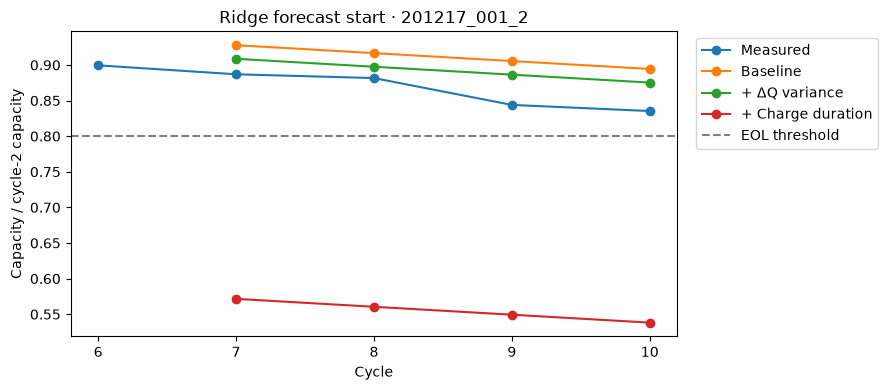

In [37]:
cutoff = ridge.CUTOFF
cycles = range(cutoff, cutoff + 5)

capacity = run["measured_capacity"].reindex(cycles).to_frame("Measured")

for model, forecast in run["forecasts"].items():
    first_four = forecast[:4]
    forecast_cycles = range(cutoff + 1, cutoff + 1 + len(first_four))
    capacity[model] = pd.Series(first_four, index=forecast_cycles)

display(capacity.round(4))

ax = capacity.plot(marker="o", figsize=(9, 4))
ax.axhline(ridge.FRACTION, color="gray", linestyle="--", label="EOL threshold")
ax.set(
    title=f"Ridge forecast start · {run_id.removeprefix('LR1865SZ_cycles')}",
    xlabel="Cycle",
    ylabel="Capacity / cycle-2 capacity",
    xticks=list(cycles),
)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

I used cycle 6 as the last observed cycle and compared the Ridge forecasts with measured capacity over cycles 7–10.
The baseline and + ΔQ variance both overestimated capacity at every forecast cycle, with + ΔQ variance consistently closer to the measurements.
Adding charge duration pushed the cycle-7 prediction down to 57.16% of cycle-2 capacity, versus 88.69% measured, so the forecast crossed the 80% EOL threshold too early.

Fine tuning can performed on setting strong ridge regularization. 